# The movie graph: a quick start

Movies, the people who made them, and their studios and distributors, as one network. Build it first, from
the data folder:

```bash
cd data/raw && mkdir -p features/graph && duckdb < ../../scripts/network/graph_tables.sql
../../.venv/bin/python ../../scripts/network/build_graph.py
```

That writes `nodes.csv`, `edges.csv` and `movie_graph.graphml` to `data/raw/features/graph/`. The docstring of
`scripts/network/build_graph.py` lists every field. This notebook loads the graph, describes it, and shows
three ways in: one-mode projections, a collaborator network, and a leakage-safe cast measure tested against
profit.

In [1]:
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats

G = Path("../data/raw/features/graph")
SEED = 1
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

nodes = pd.read_csv(G / "nodes.csv", dtype={"id": str}, low_memory=False).set_index("id")
edges = pd.read_csv(G / "edges.csv", dtype={"source": str, "target": str})
print(nodes.type.value_counts().to_string())
print(f"\n{len(edges):,} edges")
print(edges.role.value_counts().to_string())

type
person         90295
movie          12673
studio          5310
distributor     1992

278,292 edges
role
actor              123332
writer              31319
producer            29417
studio              20410
editor              16360
distributor         15671
composer            14581
director            14035
cinematographer     13167


## Loading it as a graph

`nodes.csv` and `edges.csv` are the plain version; `movie_graph.graphml` is the same graph for networkx
(`nx.read_graphml`, about a minute) or igraph. Here the graph is built from the tables, as an undirected
bipartite graph: people, studios and distributors on one side, movies on the other. Multiple roles collapse
into one edge with a `roles` list.

In [2]:
B = nx.Graph()
B.add_nodes_from((i, {"type": t}) for i, t in nodes.type.items())
for (s, t), grp in edges.groupby(["source", "target"]):
    B.add_edge(s, t, roles=sorted(set(grp.role)), year=grp.year.iloc[0])
deg = pd.Series(dict(B.degree()))
print(f"{B.number_of_nodes():,} nodes, {B.number_of_edges():,} edges, "
      f"{nx.number_connected_components(B):,} components; largest has "
      f"{len(max(nx.connected_components(B), key=len)):,} nodes")

110,270 nodes, 262,942 edges, 39 components; largest has 109,758 nodes


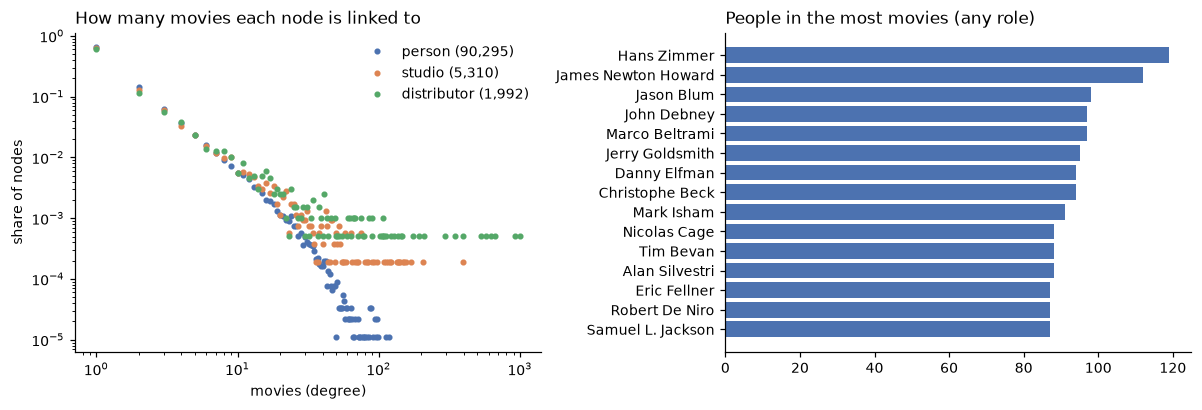

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for t, c in (("person", "#4c72b0"), ("studio", "#dd8452"), ("distributor", "#55a868")):
    k = deg[nodes.index[nodes.type == t]]
    vals, counts = np.unique(k, return_counts=True)
    axes[0].loglog(vals, counts / counts.sum(), "o", ms=3, color=c, label=f"{t} ({len(k):,})")
axes[0].set_xlabel("movies (degree)"); axes[0].set_ylabel("share of nodes")
axes[0].set_title("How many movies each node is linked to", loc="left"); axes[0].legend(frameon=False)
top = deg[nodes.index[nodes.type == "person"]].sort_values().tail(15)
axes[1].barh([nodes.label[i] for i in top.index], top.values, color="#4c72b0")
axes[1].set_title("People in the most movies (any role)", loc="left")
plt.tight_layout(); plt.show()

Studio and distributor names aren't merged, so one company can appear under several names. Merge them
before you rank studios.

## One-mode projections

Most questions are about one kind of node. Two projections cover most of them:

- **actors**, linked when they share a film in which both are billed in the top five;
- **movies**, linked when they share a director, writer or top-five actor (a film's "crew overlap").

Both are restricted here to the clean sample, the films with a usable budget and gross.

In [4]:
clean = set(nodes.index[(nodes.type == "movie") & (nodes.clean == 1)])
cast = edges[(edges.role == "actor") & (edges.ordering <= 5) & edges.target.isin(clean)]

A = nx.Graph()
for movie, grp in cast.groupby("target"):
    for a, b in combinations(sorted(grp.source), 2):
        if A.has_edge(a, b):
            A[a][b]["weight"] += 1
        else:
            A.add_edge(a, b, weight=1)
giant = A.subgraph(max(nx.connected_components(A), key=len)).copy()
print(f"actor projection: {A.number_of_nodes():,} actors, {A.number_of_edges():,} links; "
      f"giant component {giant.number_of_nodes():,} actors")

key = edges[edges.target.isin(clean) & (edges.role.isin(["director", "writer"])
            | ((edges.role == "actor") & (edges.ordering <= 5)))]
M = nx.Graph()
for person, grp in key.groupby("source"):
    for a, b in combinations(sorted(set(grp.target)), 2):
        M.add_edge(a, b, weight=M[a][b]["weight"] + 1 if M.has_edge(a, b) else 1)
print(f"movie projection: {M.number_of_nodes():,} movies, {M.number_of_edges():,} links")

actor projection: 12,353 actors, 62,027 links; giant component 11,230 actors


movie projection: 6,756 movies, 191,343 links


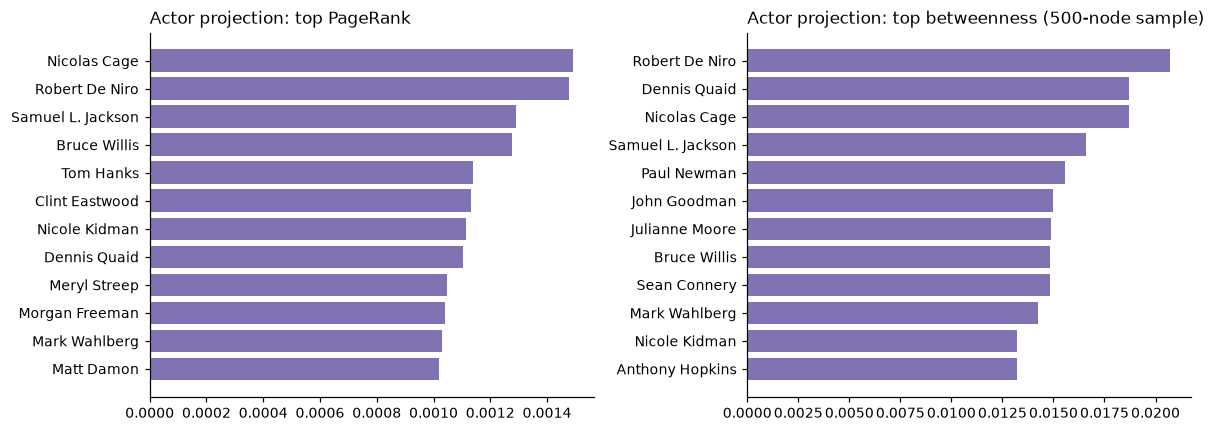

In [5]:
pr = pd.Series(nx.pagerank(giant, weight="weight"))
bt = pd.Series(nx.betweenness_centrality(giant, k=500, seed=SEED, weight=None))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, s, title in ((axes[0], pr, "PageRank"), (axes[1], bt, "betweenness (500-node sample)")):
    top = s.sort_values().tail(12)
    ax.barh([nodes.label[i] for i in top.index], top.values, color="#8172b2")
    ax.set_title(f"Actor projection: top {title}", loc="left")
plt.tight_layout(); plt.show()

## A collaborator network

The films one person worked on in any role, and the people who appear in at least two of them (top-four
billed actors and crew), coloured by role. Change `WHO` to any `nm` ID in `nodes.csv`.

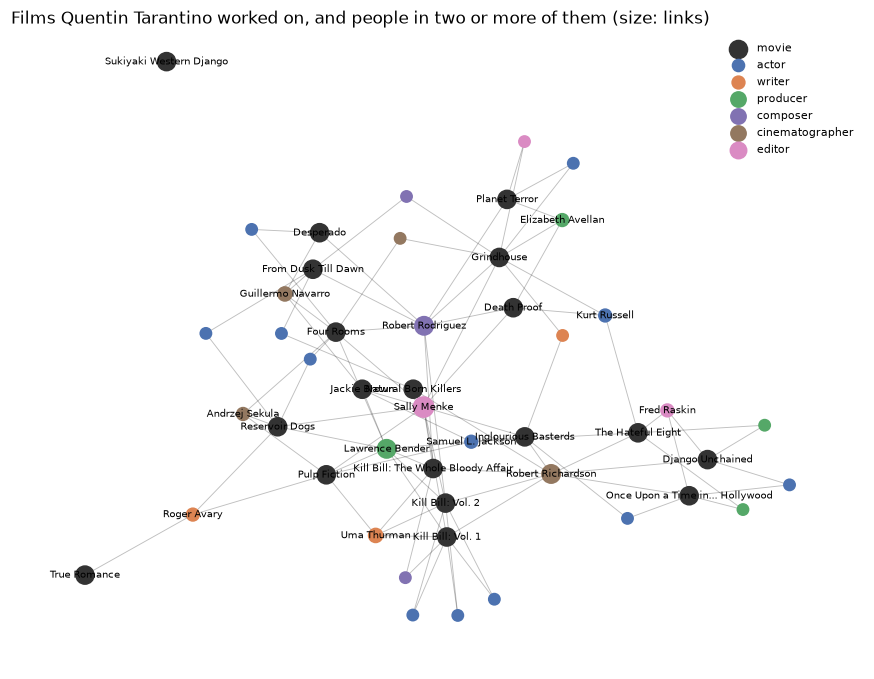

In [6]:
WHO = nodes.index[(nodes.label == "Quentin Tarantino")][0]
films = set(edges.target[edges.source == WHO])
around = edges[edges.target.isin(films) & (edges.source != WHO)
               & ((edges.role != "actor") | (edges.ordering <= 4))
               & ~edges.role.isin(["studio", "distributor"])]
around = around[around.groupby("source").target.transform("nunique") >= 2]  # people in 2+ of these films
E = nx.Graph()
for f in films:
    E.add_node(f, kind="movie")
for _, r in around.iterrows():
    E.add_node(r.source, kind=r.role); E.add_edge(r.source, r.target)
colours = {"movie": "#333333", "actor": "#4c72b0", "director": "#c44e52", "writer": "#dd8452",
           "producer": "#55a868", "composer": "#8172b2", "cinematographer": "#937860", "editor": "#da8bc3"}
pos = nx.spring_layout(E, seed=SEED, k=0.35)
fig, ax = plt.subplots(figsize=(10, 7.5))
nx.draw_networkx_edges(E, pos, ax=ax, alpha=0.25, width=0.6)
for kind, c in colours.items():
    ns = [n for n, k in E.nodes(data="kind") if k == kind]
    nx.draw_networkx_nodes(E, pos, nodelist=ns, ax=ax, node_color=c, node_size=[140 if kind == "movie" else 25 + 15 * E.degree(n) for n in ns], label=kind)
labels = {n: nodes.label[n] for n in E if E.nodes[n]["kind"] == "movie" or E.degree(n) >= 3}
nx.draw_networkx_labels(E, pos, labels, ax=ax, font_size=6.5)
ax.legend(frameon=False, fontsize=7, loc="upper right"); ax.axis("off")
ax.set_title(f"Films {nodes.label[WHO]} worked on, and people in two or more of them (size: links)", loc="left")
plt.show()

## A leakage-safe cast measure

Success makes actors central, so a cast measure that uses a film's own result, or later films, would leak
the outcome into the predictor. Here each clean film's cast experience is computed only from films released
**before** it: the mean number of earlier films (in the 10,000+ vote set) of its top three billed actors.
Then it's compared with the film's gross multiple, with budget and year held fixed.

6,804 clean films | cast's prior films vs ln(multiple): rho -0.162 raw, -0.085 net of budget and year (p = 2.5e-12)


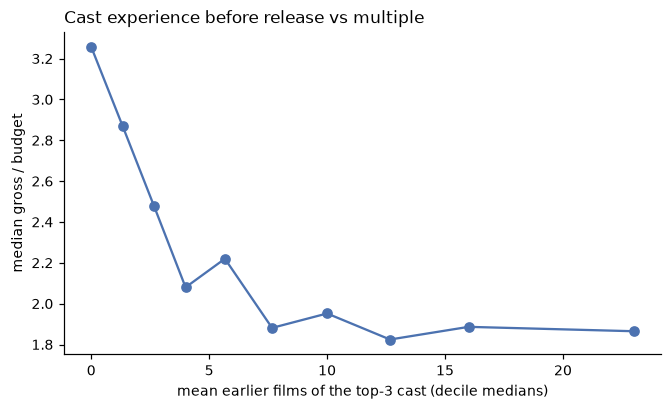

In [7]:
act = edges[(edges.role == "actor")].merge(nodes[["year"]], left_on="target", right_index=True, suffixes=("", "_m"))
first = act.groupby("source").year.apply(sorted).to_dict()
import bisect
def prior_films(person, y):
    return bisect.bisect_left(first.get(person, []), y)
top3 = edges[(edges.role == "actor") & (edges.ordering <= 3) & edges.target.isin(clean)]
exp = top3.assign(prior=[prior_films(p, y) for p, y in zip(top3.source, top3.year)]).groupby("target").prior.mean()
cm = nodes.loc[list(clean), ["year", "budget_usd", "multiple"]].join(exp.rename("cast_prior_films")).dropna()
cm["log_mult"], cm["log_budget"] = np.log(cm.multiple), np.log(cm.budget_usd)

def rank_partial(y, x, z):
    r = stats.rankdata
    Z = np.column_stack([np.ones(len(y))] + [r(c) for c in z.T])
    res = lambda v: r(v) - Z @ np.linalg.lstsq(Z, r(v), rcond=None)[0]
    return stats.pearsonr(res(x), res(y))
rho_raw = stats.spearmanr(cm.cast_prior_films, cm.log_mult)[0]
rho, p = rank_partial(cm.log_mult.values, cm.cast_prior_films.values, cm[["log_budget", "year"]].values)
print(f"{len(cm):,} clean films | cast's prior films vs ln(multiple): rho {rho_raw:+.3f} raw, "
      f"{rho:+.3f} net of budget and year (p = {p:.2g})")

fig, ax = plt.subplots(figsize=(7, 3.8))
bins = pd.qcut(cm.cast_prior_films.rank(method="first"), 10, labels=False)
g = cm.groupby(bins)
ax.plot(g.cast_prior_films.median(), np.exp(g.log_mult.median()), "o-", color="#4c72b0")
ax.set_xlabel("mean earlier films of the top-3 cast (decile medians)"); ax.set_ylabel("median gross / budget")
ax.set_title("Cast experience before release vs multiple", loc="left")
plt.show()

## Ideas to take further

- Communities in the actor or movie projection (Louvain or Infomap) and whether some communities make more
  money than others, against a degree-preserving null.
- Rolling networks: rebuild the projection from films up to year *t* and track who becomes central.
- Studio-level networks once studio names are merged.
- Assortativity: do high-multiple films share crews more than chance?